# 72 — Visual goal-conditioned policies and VLA intuition

This robot-learning practice studies one central idea: **the correct action depends on both what the agent sees and what it is asked to do**. We first use a goal image, then replace the goal channel with a language instruction. The models are intentionally small; the aim is intuition rather than reproducing a large robotics system.

Companion note: [Visual goal-conditioned policies and VLA intuition](../notes/17-robot-learning/visual-goal-conditioned-policies-and-vla.md).

In [1]:
from functools import partial
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from cs231n_practice.goal_conditioning import (
    TinyVisionLanguageActionPolicy,
    VisualGoalGridWorld,
    VisualGoalPolicy,
    build_goal_conditioned_demonstrations,
    evaluate_closed_loop,
    instruction_policy_action,
    plot_demonstration_examples,
    plot_experiment_losses,
    plot_failed_rollouts,
    plot_policy_action_fields,
    plot_policy_rollouts,
    plot_state_goal_split,
    plot_validation_mistakes,
    run_goal_conditioning_experiment,
    rollout_policy_with_loop_recovery,
    split_demonstrations,
    visual_goal_policy_action,
)

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using {DEVICE}")

Using mps


## 1. A small visual navigation world

The agent moves on a $6\times6$ grid. Channel 0 marks obstacles, channel 1 marks the agent, and channel 2 marks the requested goal. Each goal now has its own obstacle layout, so changing the requested task can change both the goal channel and the traversable environment. This creates different navigation problems instead of asking every target to share one map.

This choice has a trade-off. The advantage is harder, more varied navigation with different detours and failure modes. The disadvantage is that each obstacle layout becomes an indirect clue to its associated target. A model may learn `layout A → top left`, for example, instead of relying fully on the goal channel or instruction. Therefore this experiment is useful for studying navigation across several fixed tasks, but it is not a clean test of whether the model independently understands the requested goal. Such a test would combine every obstacle layout with multiple goals or randomize layouts independently of the target.

In [2]:
world = VisualGoalGridWorld(
    obstacles_by_goal=(
        frozenset({(2, 0), (2, 1), (2, 2), (4, 4)}),
        frozenset({(0, 2), (1, 2), (2, 2), (4, 4)}),
        frozenset({(1, 2), (2, 2), (3, 2), (5, 4)}),
    )
)
print(f"{world.grid_size} x {world.grid_size} grid")
for goal_index, goal_name in enumerate(world.goal_names):
    print(
        f"{goal_name:>12}: {len(world.reachable_states(goal_index))} reachable states; "
        f"obstacles = {sorted(world.obstacles_for_goal(goal_index))}"
    )
print(f"actions: {world.action_names}")

6 x 6 grid
    top left: 32 reachable states; obstacles = [(2, 0), (2, 1), (2, 2), (4, 4)]
   top right: 32 reachable states; obstacles = [(0, 2), (1, 2), (2, 2), (4, 4)]
bottom right: 32 reachable states; obstacles = [(1, 2), (2, 2), (3, 2), (5, 4)]
actions: ('up', 'right', 'down', 'left')


### Render a goal-conditioned observation

`VisualGoalGridWorld.render` fills the three channels at the obstacle, agent, and goal locations. We visualize its output below.

Each observation has shape `(3, 6, 6)`, following PyTorch's channel-first image convention `(channels, height, width)`. The grid has six rows and six columns, while its three channels store different kinds of information:

- channel 0 is a $6\times6$ obstacle map: obstacle cells are 1 and other cells are 0;
- channel 1 is a $6\times6$ agent map: only the agent's current cell is 1;
- channel 2 is a $6\times6$ goal map: only the requested goal cell is 1.

The channels are similar to separate red, green, and blue image channels, except that here they have explicit semantic meanings. Stacking many observations later produces shape `(N, 3, 6, 6)`, where `N` is the number of examples.

Matplotlib expects image channels last, with shape `(height, width, channels)`. Therefore, `observation.transpose(1, 2, 0)` changes `(3, 6, 6)` into `(6, 6, 3)` for visualization; it does not change the underlying grid information.

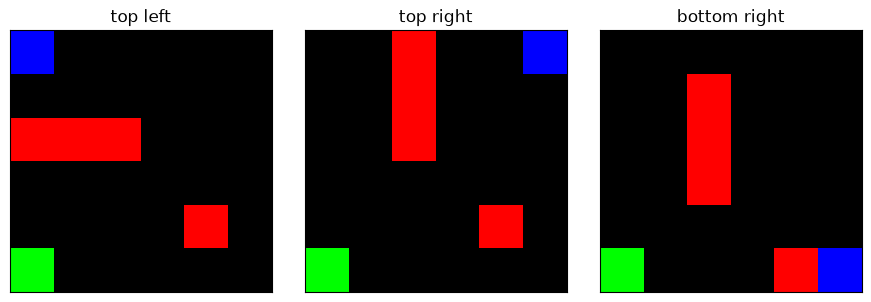

In [3]:
example_state = (5, 0)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for goal_index, axis in enumerate(axes):
    observation = world.render(example_state, goal_index)
    axis.imshow(observation.transpose(1, 2, 0))
    axis.set_title(world.goal_names[goal_index])
    axis.set_xticks([]); axis.set_yticks([])
plt.tight_layout()

## 2. A goal-conditioned expert

For this known grid we can compute shortest-path distances with **breadth-first search (BFS)**. We begin at the goal and expand outward one grid step at a time. Therefore, cells discovered first are one step away, cells discovered in the next layer are two steps away, and so on.

`deque` means **double-ended queue**. Here we use it as a first-in, first-out queue: `append(...)` adds a state to the right end, while `popleft()` removes the oldest state from the left end. This ordering is what makes BFS process all states at distance $d$ before states at distance $d+1$. The expert then selects the action whose next state has the smallest recorded distance to the requested goal.

In [4]:
distance_maps = [
    world.shortest_path_distances(goal_index)
    for goal_index in range(len(world.goals))
]

In [5]:
[len(distances) for distances in distance_maps]

[32, 32, 32]

### Select the expert action

`world.expert_action` evaluates all four next states with the distance map and returns the index of the minimum. A blocked action leaves the state unchanged, so it will not improve the distance. The implementation now lives in the reusable module, while this notebook shows its behavior.

In [6]:
for goal_index, goal_name in enumerate(world.goal_names):
    action = world.expert_action(example_state, goal_index)
    print(
        f"At {example_state}, goal '{goal_name}' -> "
        f"{world.action_names[action]}"
    )

At (5, 0), goal 'top left' -> up
At (5, 0), goal 'top right' -> up
At (5, 0), goal 'bottom right' -> up


## 3. Build demonstrations

We enumerate every reachable non-goal state with every goal. Each demonstration contains the current visual observation, its goal identity, and the expert action.

In [7]:
demonstrations = build_goal_conditioned_demonstrations(world)
train_indices, validation_indices = split_demonstrations(
    len(demonstrations.actions), seed=SEED
)
print(f"{len(train_indices)} training and {len(validation_indices)} validation demonstrations")

74 training and 19 validation demonstrations


### Inspect the dataset and split

The split is performed over complete `(state, goal)` demonstrations. The training and validation sets therefore contain different state-goal pairs, although the same agent position or the same goal may appear in both sets as part of different pairs. The validation set measures how well the model handles held-out combinations from this small grid; it is not a test on a completely new environment.

The first visualization uses one grid per goal because the split applies to `(agent state, goal)` pairs: the same agent state can belong to training for one goal and validation for another. Blue cells are training pairs, orange cells are validation pairs, dark cells are obstacles, and the star is the goal (which has no action example).

In the example inputs below, each image is the model input and its title shows the target supplied by the expert. Red marks obstacles, green marks the agent, and blue marks the requested goal.

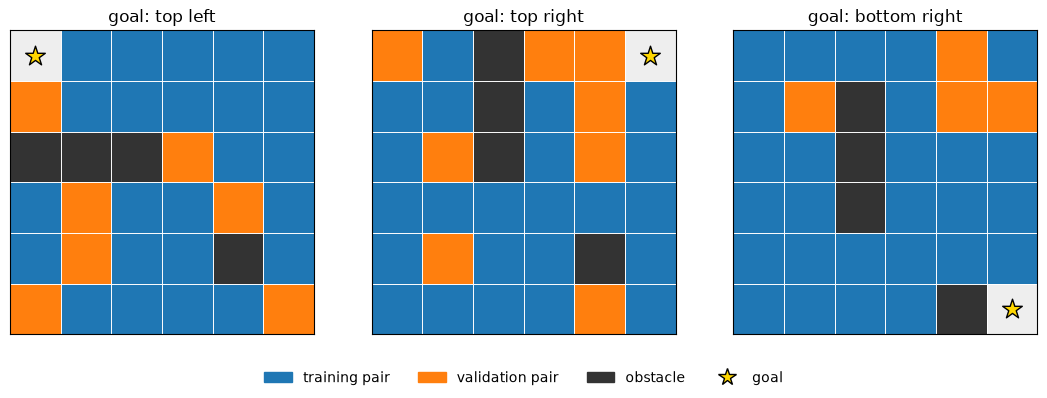

In [8]:
plot_state_goal_split(
    world, demonstrations.state_goal_pairs, train_indices
);

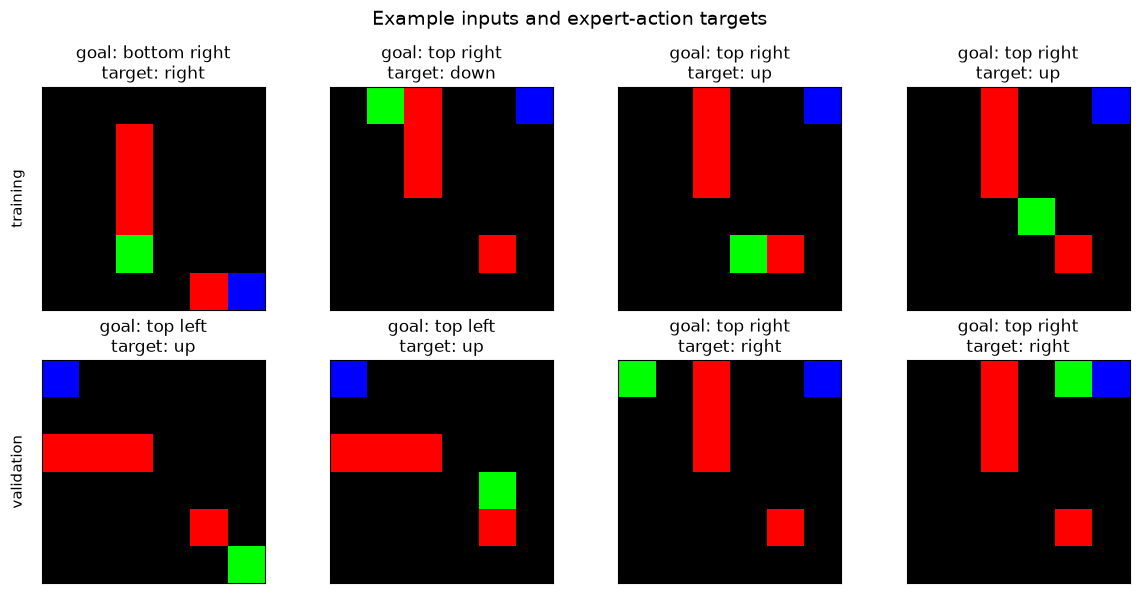

In [9]:
plot_demonstration_examples(
    world,
    demonstrations,
    {"training": train_indices, "validation": validation_indices},
);

## 4. Learn from a visual goal

The CNN receives the obstacle, agent, and goal channels together. The goal is therefore spatial: the policy can use where the desired destination lies relative to the agent. From this image-like tensor, the model must select one of four action classes: up, right, down, or left.

We assign semantic meanings to the three channels when constructing the data, but the model itself only receives numbers. It is not explicitly told what an agent, obstacle, or goal is. By learning from expert input-action pairs, it discovers numerical spatial patterns that are useful for predicting each action. This deliberately structured representation avoids the harder perception problem of recognizing those concepts in ordinary camera pixels, letting us focus on goal-conditioned policy learning.

In [10]:
visual_policy = VisualGoalPolicy(world.grid_size).to(DEVICE)
optimizer = torch.optim.Adam(visual_policy.parameters(), lr=3e-3)
train_x = demonstrations.observations[train_indices].to(DEVICE)
train_y = demonstrations.actions[train_indices].to(DEVICE)
for epoch in range(150):
    optimizer.zero_grad()
    loss = torch.nn.functional.cross_entropy(visual_policy(train_x), train_y)
    loss.backward(); optimizer.step()
print(f"final training loss: {loss.item():.4f}")

final training loss: 0.0002


## 5. Offline accuracy and closed-loop success

Classification accuracy asks whether one predicted action matches the expert on each held-out validation example. It is an **offline, one-step** metric: the predicted action is compared with the stored target, but the agent does not move.

Closed-loop evaluation repeatedly lets the policy observe, act, and receive the resulting next observation. A rollout is successful if the agent reaches its requested goal within `maximum_steps=30`. Thirty steps is a generous horizon for this $6\times6$ grid, whose useful shortest paths are much shorter, while still guaranteeing that evaluation terminates. If a policy repeatedly selects a blocked action, cycles between states, or follows an unnecessarily long route, the rollout stops after 30 actions and counts as a failure.

Closed-loop success is therefore stricter: every prediction changes the input to the next prediction, so errors can accumulate. However, an action that differs from the expert label need not cause failure because another route may still reach the same goal. Here, one-step accuracy is measured only on validation demonstrations, while the final closed-loop evaluation starts from every available state-goal pair in the small grid.

In [11]:
visual_policy.eval()
with torch.no_grad():
    validation_logits = visual_policy(
        demonstrations.observations[validation_indices].to(DEVICE)
    )
validation_predictions = validation_logits.argmax(dim=1).cpu()
validation_accuracy = (
    validation_predictions == demonstrations.actions[validation_indices]
).float().mean().item()

visual_action = partial(visual_goal_policy_action, visual_policy, world)
visual_success, visual_rollouts = evaluate_closed_loop(
    world, visual_action, demonstrations.state_goal_pairs
)
print(f"validation action accuracy: {validation_accuracy:.3f}")
print(f"closed-loop success: {visual_success:.3f}")

validation action accuracy: 0.737
closed-loop success: 0.720


### Inspect prediction and rollout failures

A scalar accuracy hides which spatial situations are difficult. The first diagnostic samples validation inputs for which the model's action differs from the expert label. Remember that a mismatch is not necessarily a useless action: the expert stores one shortest-path choice, while another action might still lead to the goal.

The second diagnostic selects up to three representative failed rollouts, preferring different requested goals when such failures are available. In each row, the left panel draws the predicted path and the right panel counts how often each state was visited. Repeated visits expose a loop or a policy that remains stuck by repeatedly choosing a blocked action. Because a rollout contains the initial state plus up to 30 resulting states, a failed trajectory may contain 31 recorded positions.

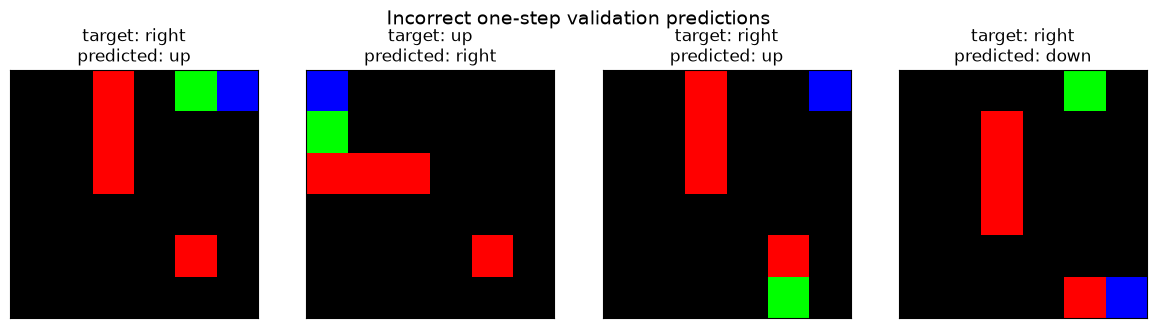

In [12]:
mistake_figure, _ = plot_validation_mistakes(
    world, demonstrations, validation_indices, validation_predictions,
    seed=SEED,
)
if mistake_figure is None:
    print("No incorrect validation predictions to visualize.")

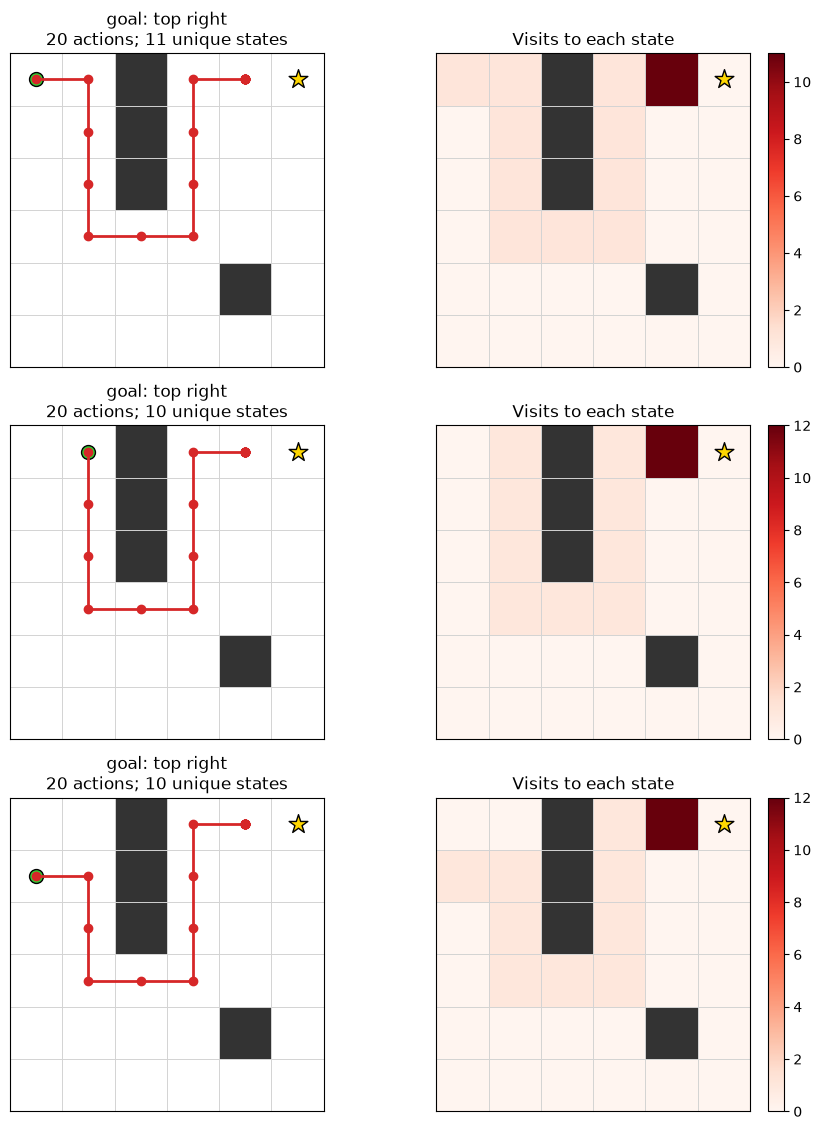

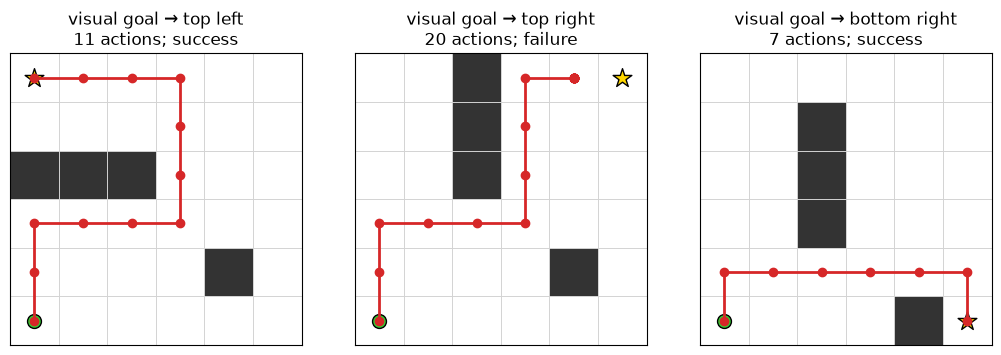

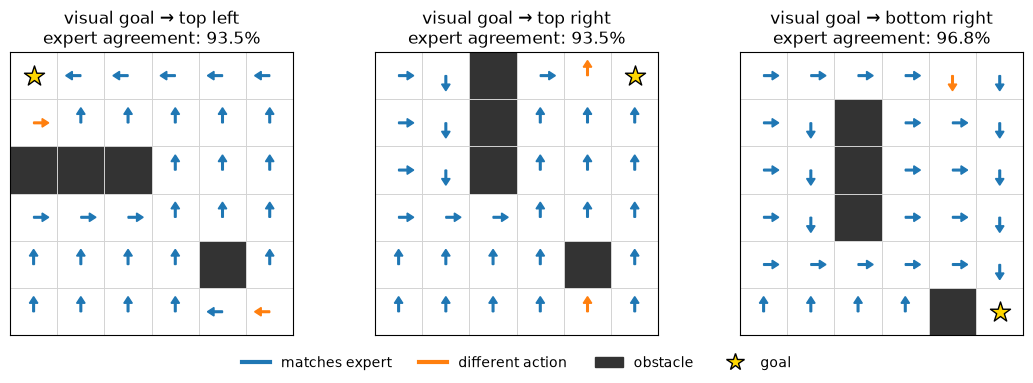

In [13]:
failure_figure, _ = plot_failed_rollouts(
    world, visual_rollouts, maximum_examples=3,
)
if failure_figure is None:
    print("No failed closed-loop rollout to visualize.")

plot_policy_rollouts(
    world, {"visual goal": visual_action}, example_state
);
plot_policy_action_fields(
    world, {"visual goal": visual_action}
);

## 6. Replace the goal image with language

Now the visual input contains only obstacles and the agent: slicing with `:2` removes the goal channel. The second input is a numerical instruction ID: 0 means *top left*, 1 means *top right*, and 2 means *bottom right*. `nn.Embedding` converts each ID into a learned vector, which is concatenated with the visual features before action classification. The human-readable strings are labels for us; this model does not tokenize or understand arbitrary text. It is a tiny analogy to a vision-language-action pipeline—not a language model.

There is now an experimental caveat: because every target has a different obstacle layout, the visual obstacle channel is correlated with the instruction. The model may partly recognize the task from the layout even without using the instruction embedding. The paths are more challenging, but this is not a clean test of whether language alone communicates the goal. A stricter comparison would reuse obstacle layouts across different instructions or randomize layouts independently of the target.

In [14]:
vla_policy = TinyVisionLanguageActionPolicy(
    grid_size=world.grid_size,
    number_instructions=len(world.goals),
    number_actions=len(world.action_names),
).to(DEVICE)
vla_optimizer = torch.optim.Adam(vla_policy.parameters(), lr=3e-3)
vla_train_x = demonstrations.observations[train_indices, :2].to(DEVICE)
vla_train_goals = demonstrations.goal_indices[train_indices].to(DEVICE)
for epoch in range(150):
    vla_optimizer.zero_grad()
    vla_loss = torch.nn.functional.cross_entropy(
        vla_policy(vla_train_x, vla_train_goals), train_y
    )
    vla_loss.backward(); vla_optimizer.step()
print(f"final VLA training loss: {vla_loss.item():.4f}")

final VLA training loss: 0.0000


### Test instruction conditioning

The shared action and rollout helpers let us inspect the same visual scene under all three instructions. Different outputs demonstrate conditioning, not three different observations. Two goals can still produce the same immediate move when that move is useful for both routes.

In [15]:
vla_policy.eval()
vla_action = partial(instruction_policy_action, vla_policy, world)
for instruction_id, name in enumerate(world.goal_names):
    action = vla_action(example_state, instruction_id)
    print(f"same scene + '{name}' -> {world.action_names[action]}")
vla_success, vla_rollouts = evaluate_closed_loop(
    world, vla_action, demonstrations.state_goal_pairs
)
print(f"closed-loop VLA success: {vla_success:.3f}")

same scene + 'top left' -> up
same scene + 'top right' -> up
same scene + 'bottom right' -> up
closed-loop VLA success: 0.720


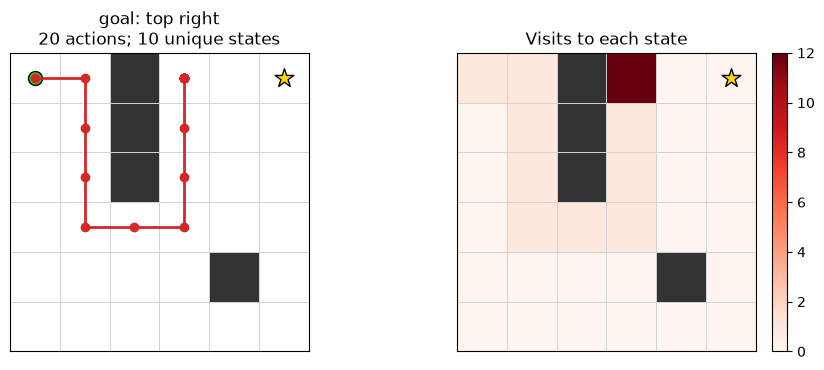

In [16]:
failure_figure, _ = plot_failed_rollouts(
    world, vla_rollouts, maximum_examples=1
)

### Visualize the complete learned action fields

The shared visualization now compares both policies. Rows select the visual-goal or instruction-goal policy, while columns select the requested goal. Each panel queries its policy at every reachable non-goal agent state. An arrow shows the action with the largest predicted logit. Blue arrows match the particular shortest-path action stored by our expert; orange arrows differ from that label, although they may still begin another successful route. An arrow pointing into a wall, obstacle, or grid boundary would leave the agent in the same state.

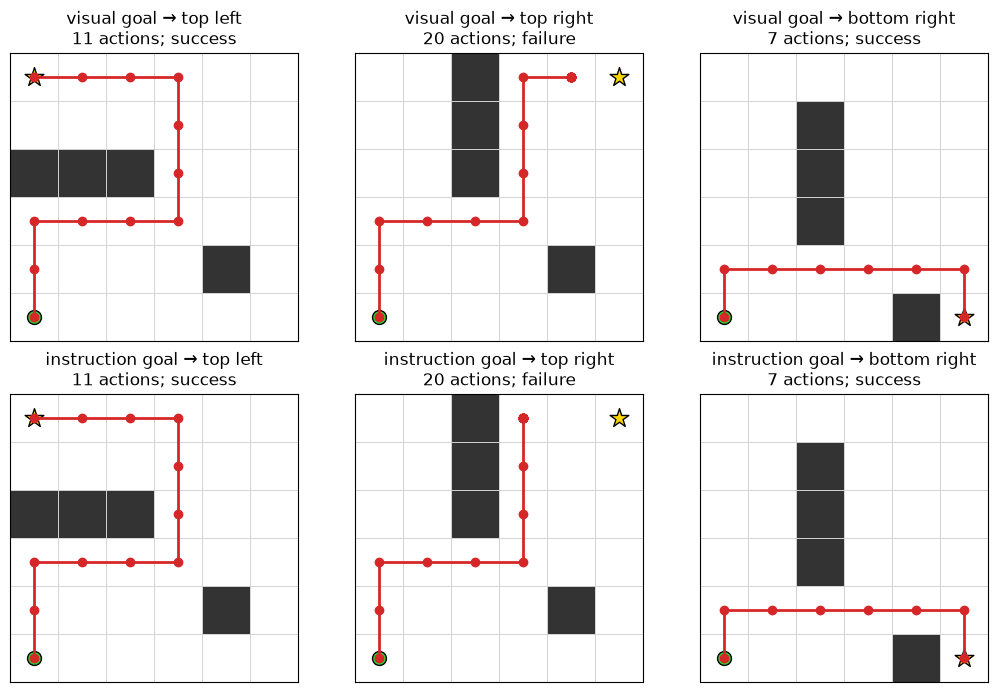

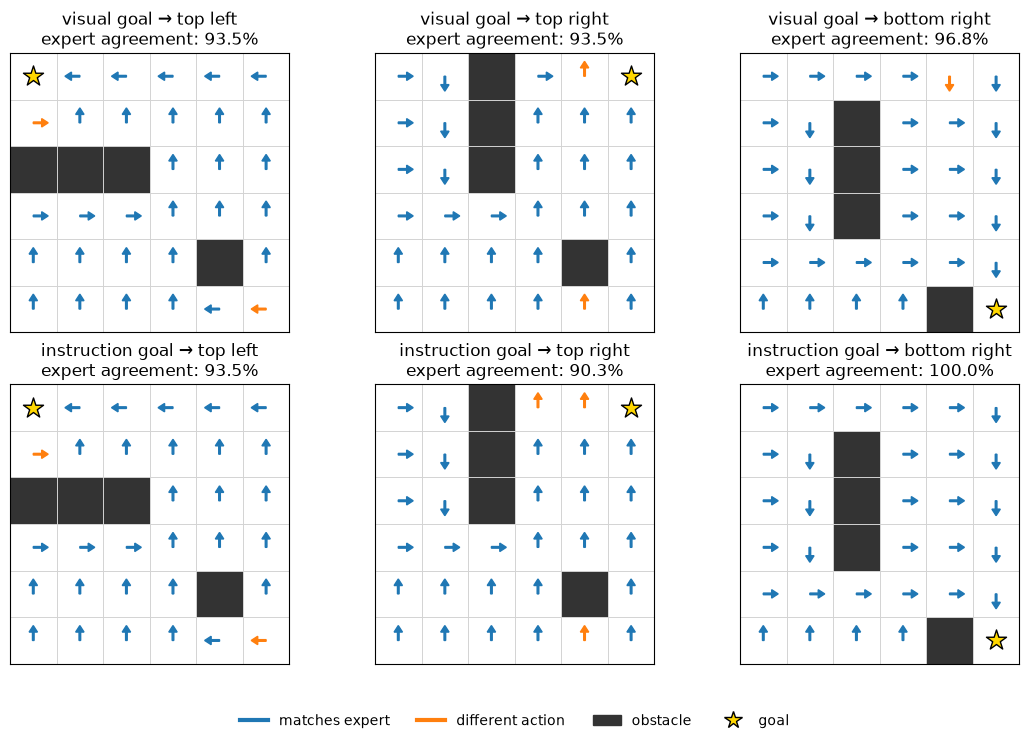

In [17]:
learned_policies = {
    "visual goal": visual_action,
    "instruction goal": vla_action,
}
plot_policy_rollouts(world, learned_policies, example_state);
plot_policy_action_fields(world, learned_policies);

## 7. From the toy model to VLA systems

Our model follows the abstract pattern **vision + instruction → action**, but real VLA systems are far richer. They may use a pretrained vision-language backbone, tokenize continuous robot actions, train across many tasks and robot datasets, and predict a short action sequence rather than one grid move.

The important conceptual bridge is conditioning: the instruction changes which behavior is appropriate without changing the current scene. Pretraining can provide broad visual and semantic knowledge, while robot demonstrations connect those representations to actions. It does not automatically solve embodiment, control precision, safety, or distribution shift.

## 8. Reflection

1. Why is the current image insufficient when the environment supports several goals?

   The same scene can require different actions for different goals. Without a goal channel or instruction, the policy does not know which behavior is requested.

2. What is the difference between a visual goal channel and an instruction embedding?

   A visual goal channel marks the goal directly in the spatial grid. An instruction embedding represents a symbolic request and must be combined with visual features by the model.

3. Why can one-step action accuracy overestimate practical policy quality?

   Small one-step errors can compound during rollout and move the agent into unfamiliar states. Closed-loop success therefore measures practical behavior better than isolated action accuracy.

4. In what sense is the second model VLA-like, and in what sense is it not a real VLA model?

   It is VLA-like because it combines a visual observation and a language-like goal identifier to predict an action. It is not a real VLA because the world, vocabulary, observations, and discrete action space are tiny and synthetic.

5. What can vision-language pretraining contribute to robot learning, and what problems remain?

   Pretraining can provide broad visual and language representations that reduce the robot-specific data required. Grounding instructions in actions, learning dynamics, handling distribution shift, safety, and reliable closed-loop control still remain.

## 9. Configurable experiment sandbox

This final sandbox repeats the complete workflow with configurable worlds and training hyperparameters. Each run creates demonstrations, makes a reproducible split, trains both policy variants, reports offline and closed-loop metrics, and visualizes their learning curves, representative rollouts, complete action fields, and failed rollouts. Larger grids contain more state-goal pairs and therefore take longer to train.

The presets deliberately share one obstacle layout across the three goals. This removes the shortcut where a goal-specific layout can reveal the requested task. Edit `EXPERIMENT_CONFIGURATIONS` or keep only one entry when you want a faster experiment.


7×7: 120 examples
  visual goal: validation=0.792, closed loop=0.783
  instruction: validation=0.792, closed loop=0.758


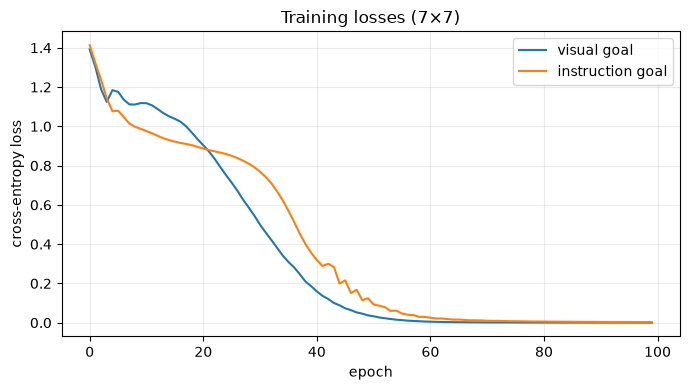

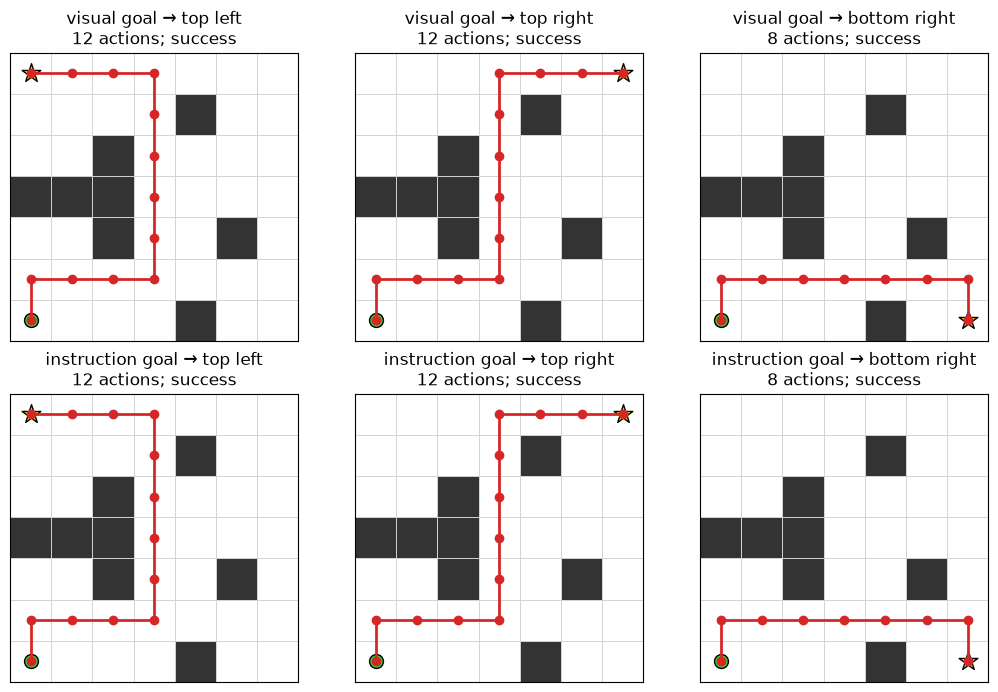

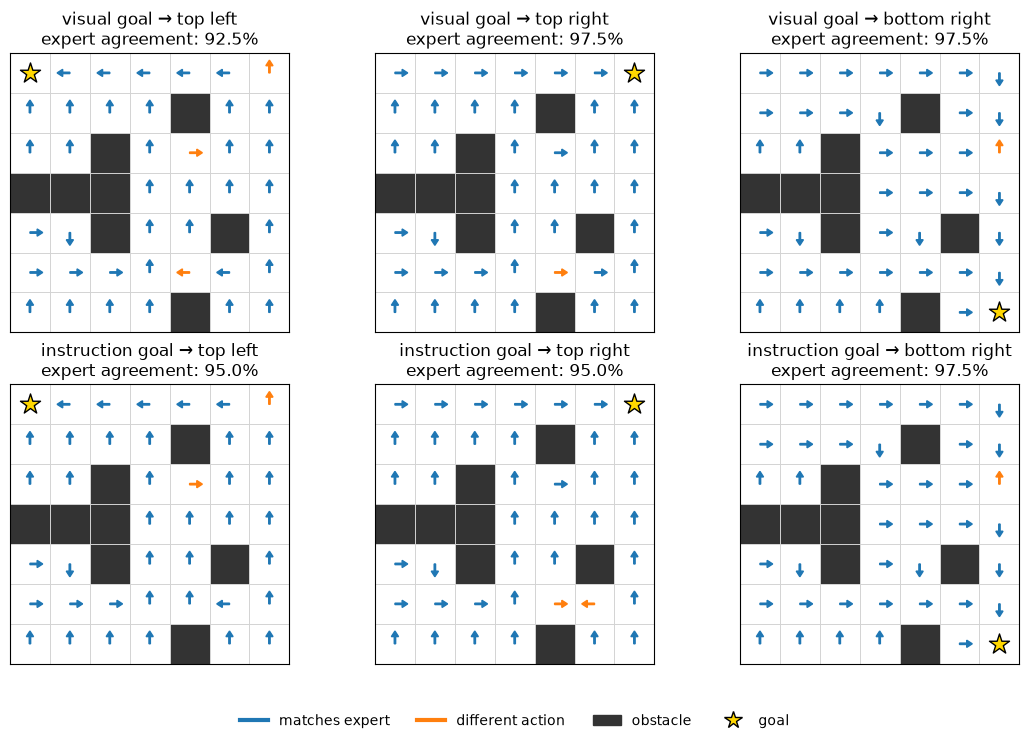

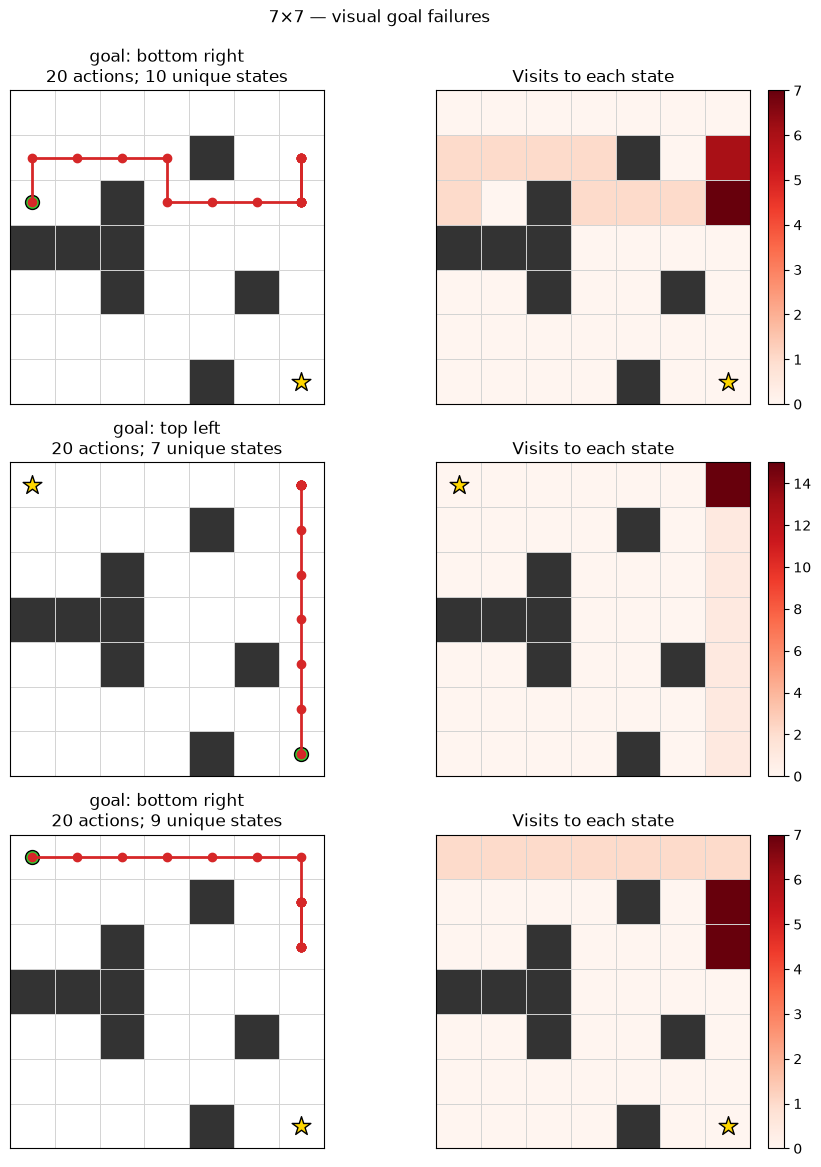

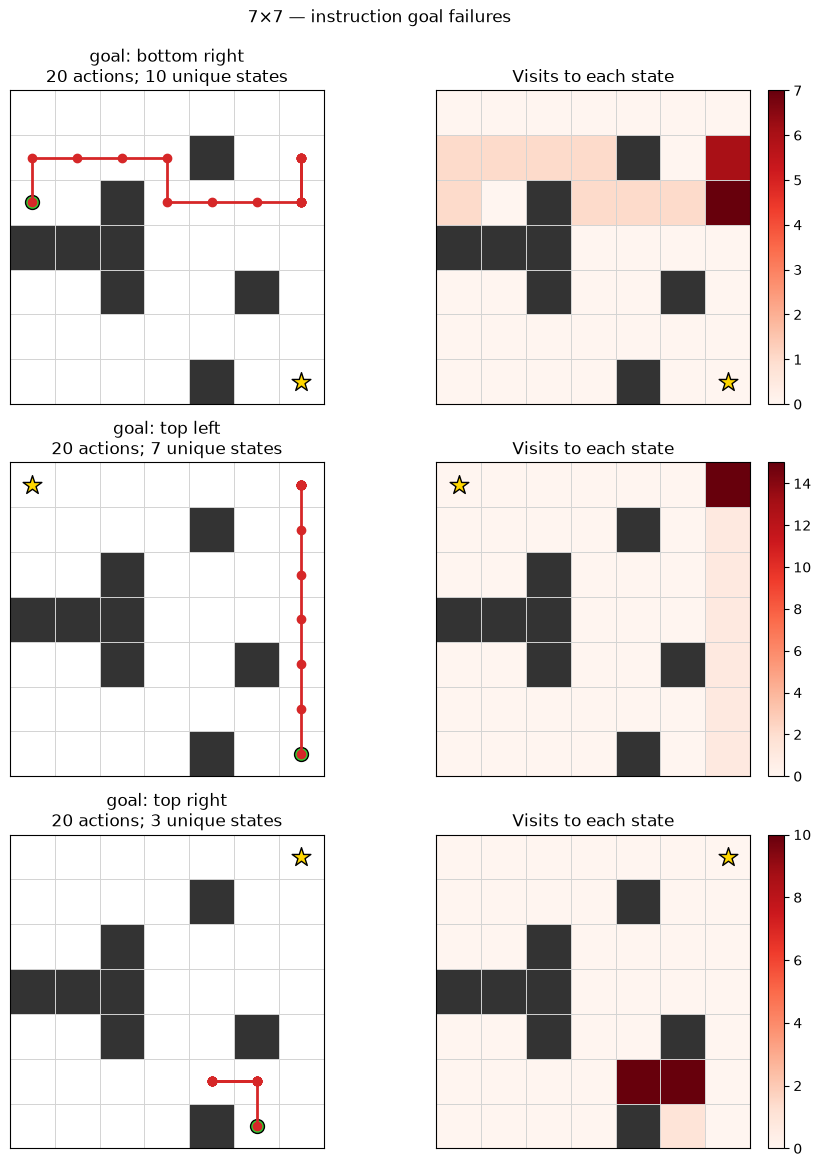


8×8: 147 examples
  visual goal: validation=0.667, closed loop=0.490
  instruction: validation=0.667, closed loop=0.449


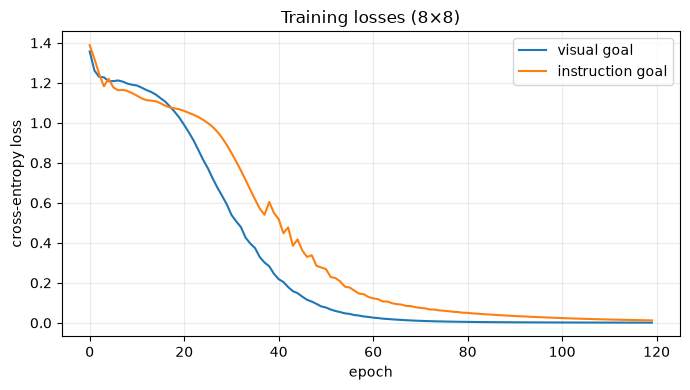

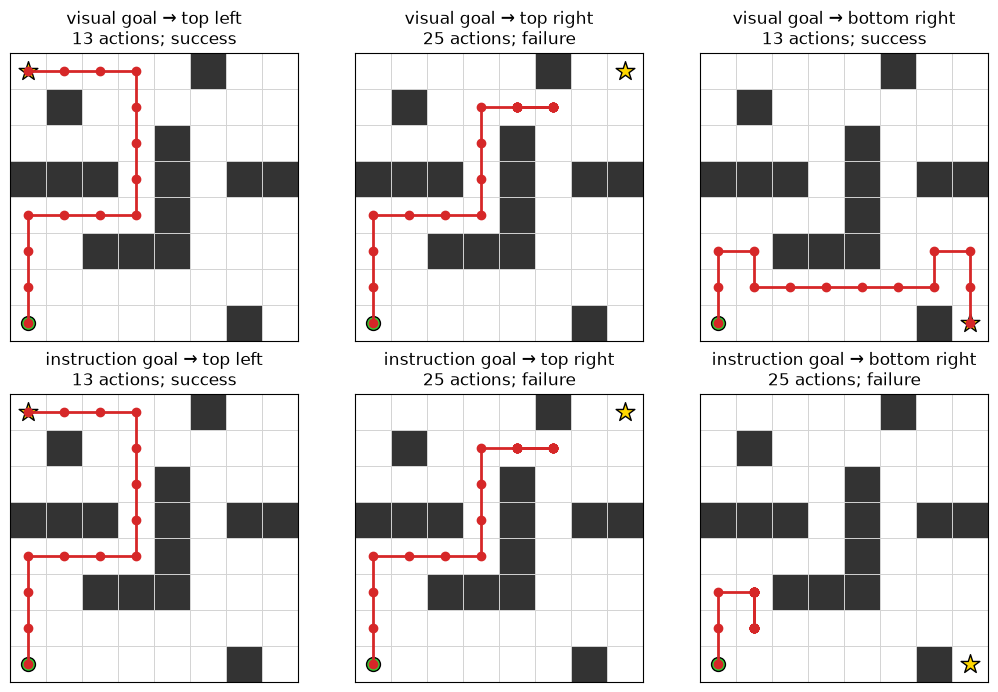

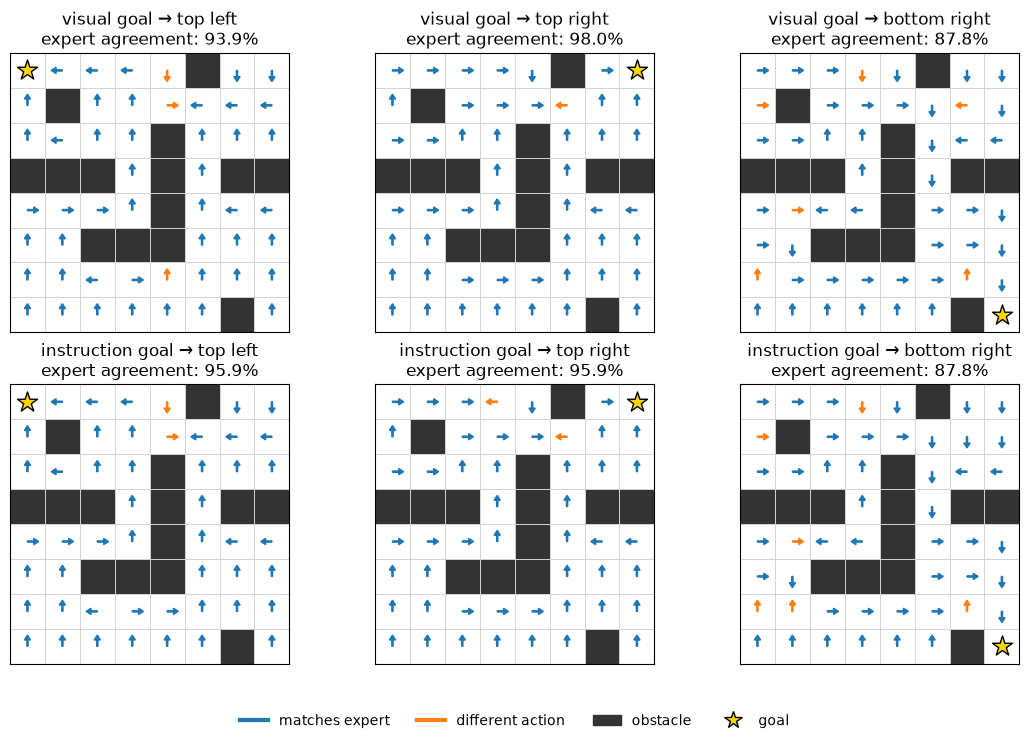

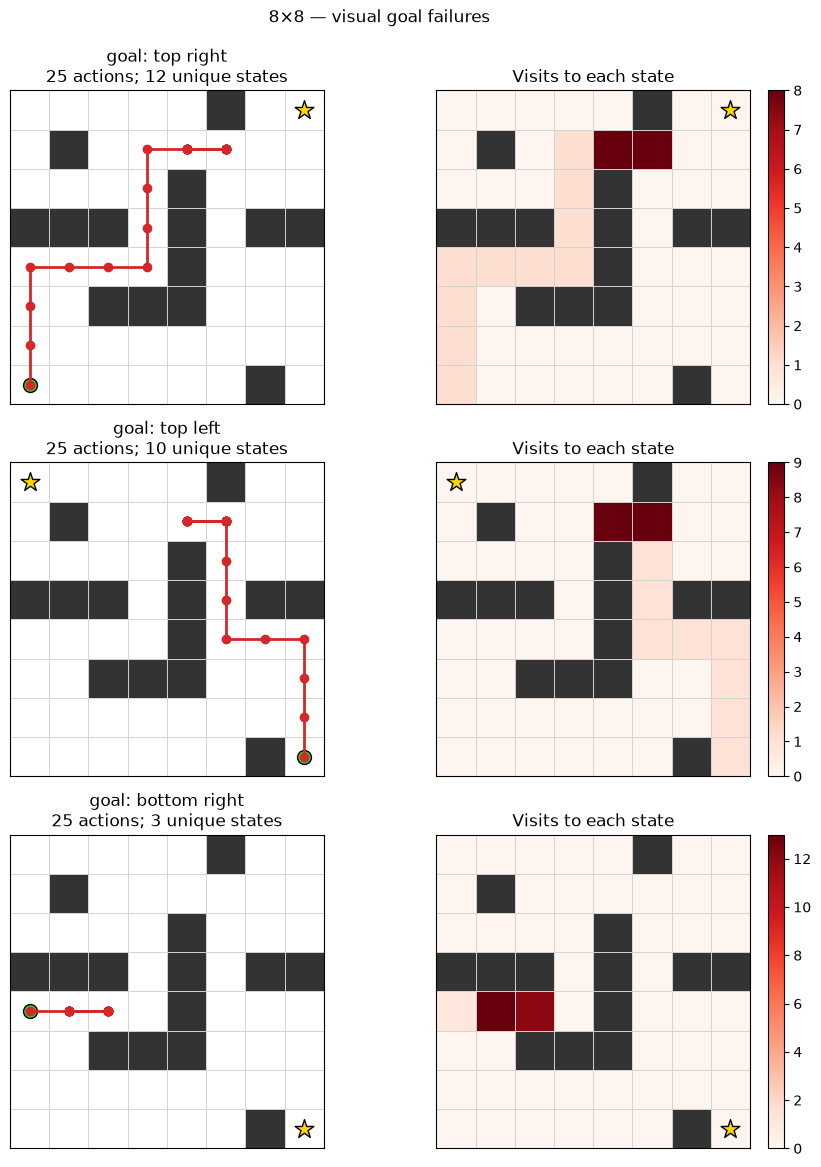

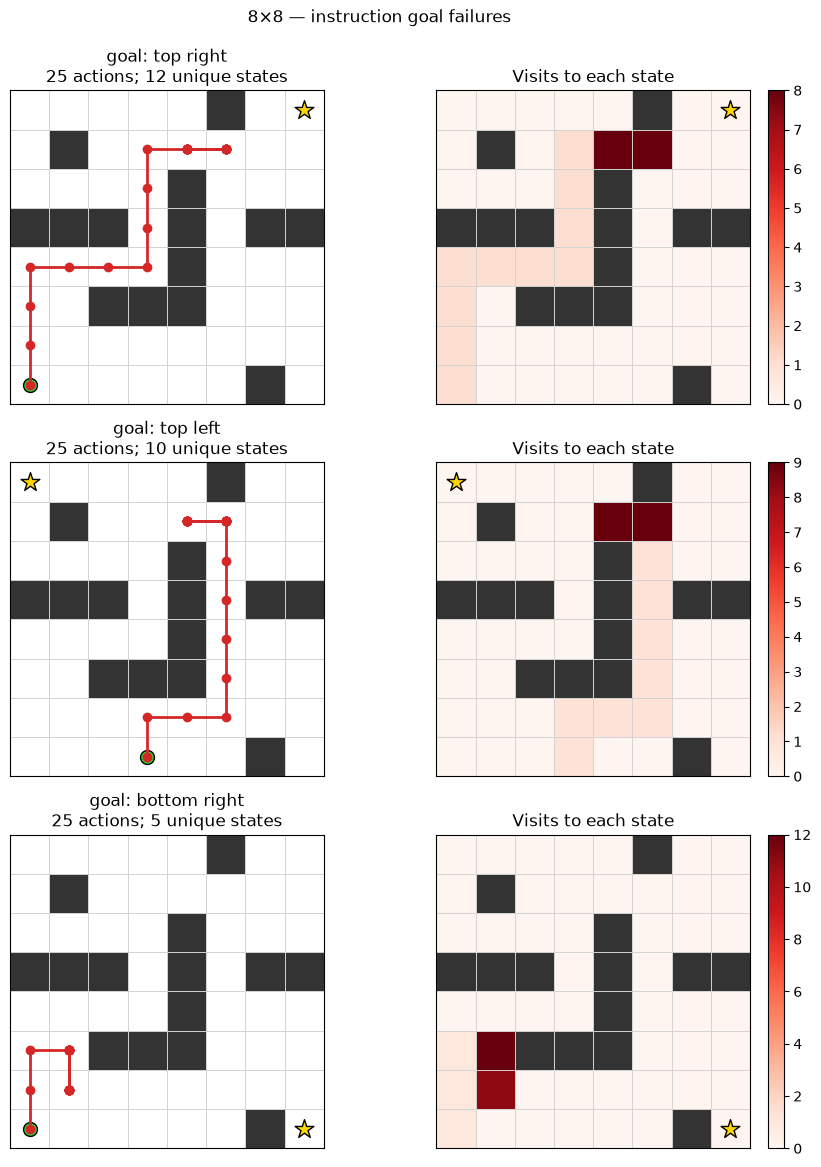


10×10: 234 examples
  visual goal: validation=0.745, closed loop=0.496
  instruction: validation=0.702, closed loop=0.466


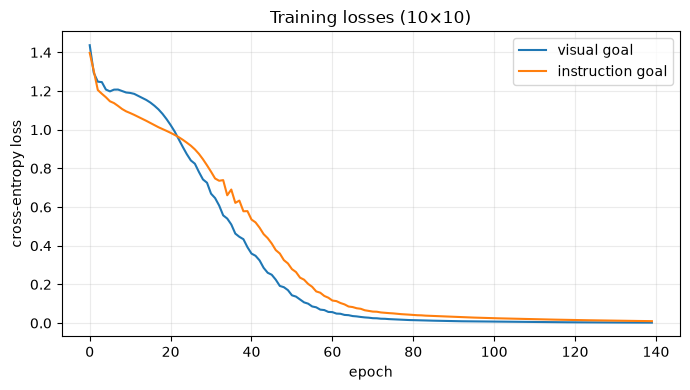

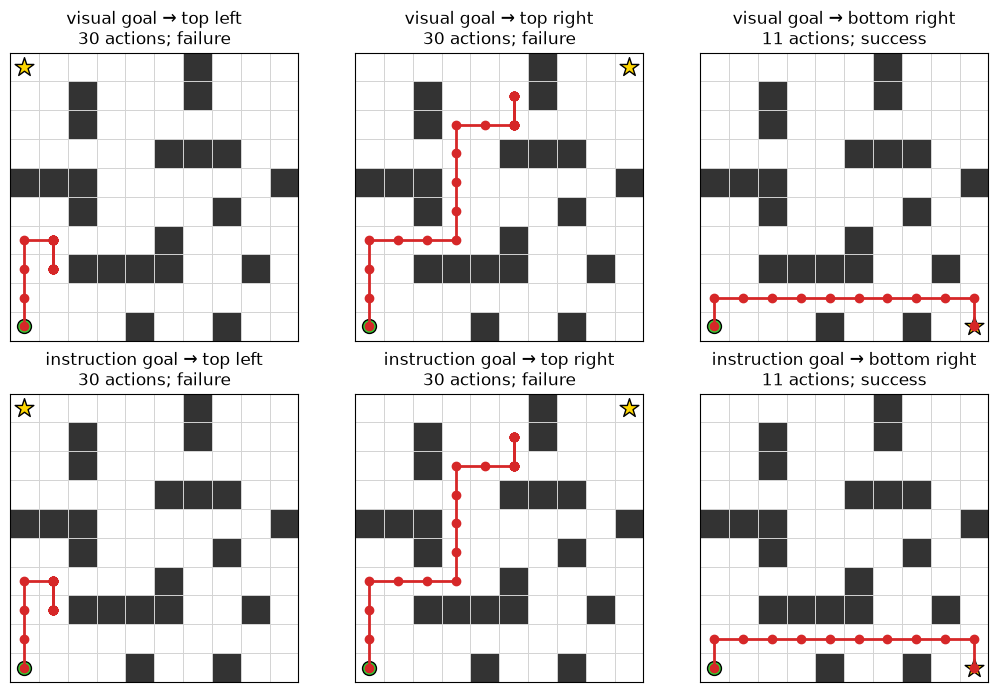

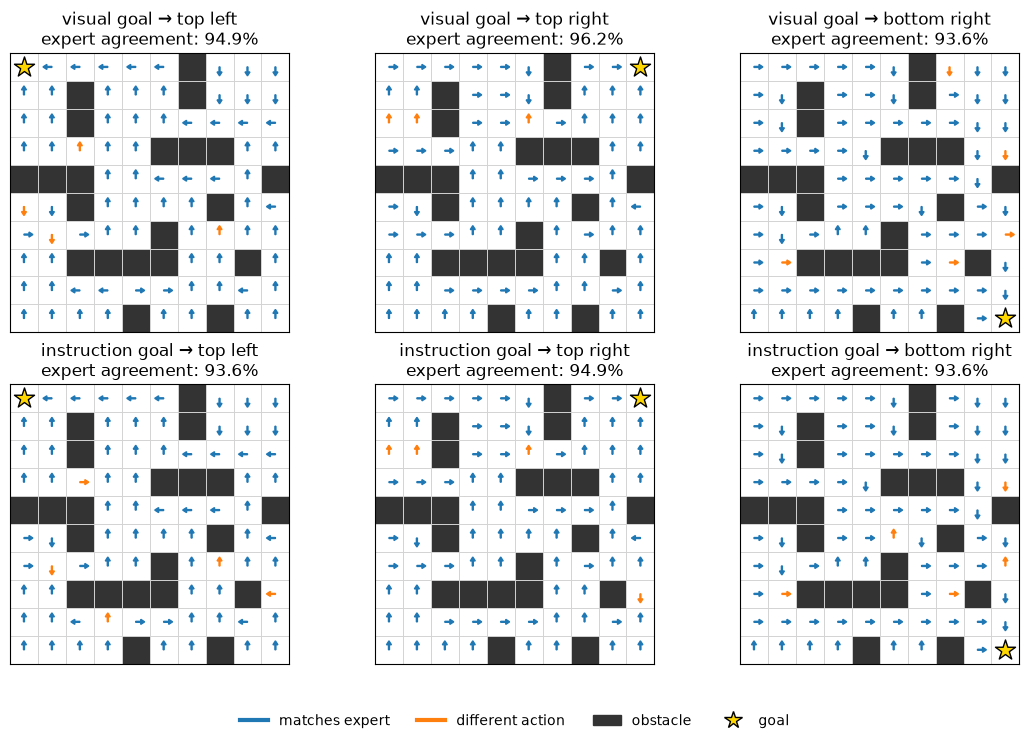

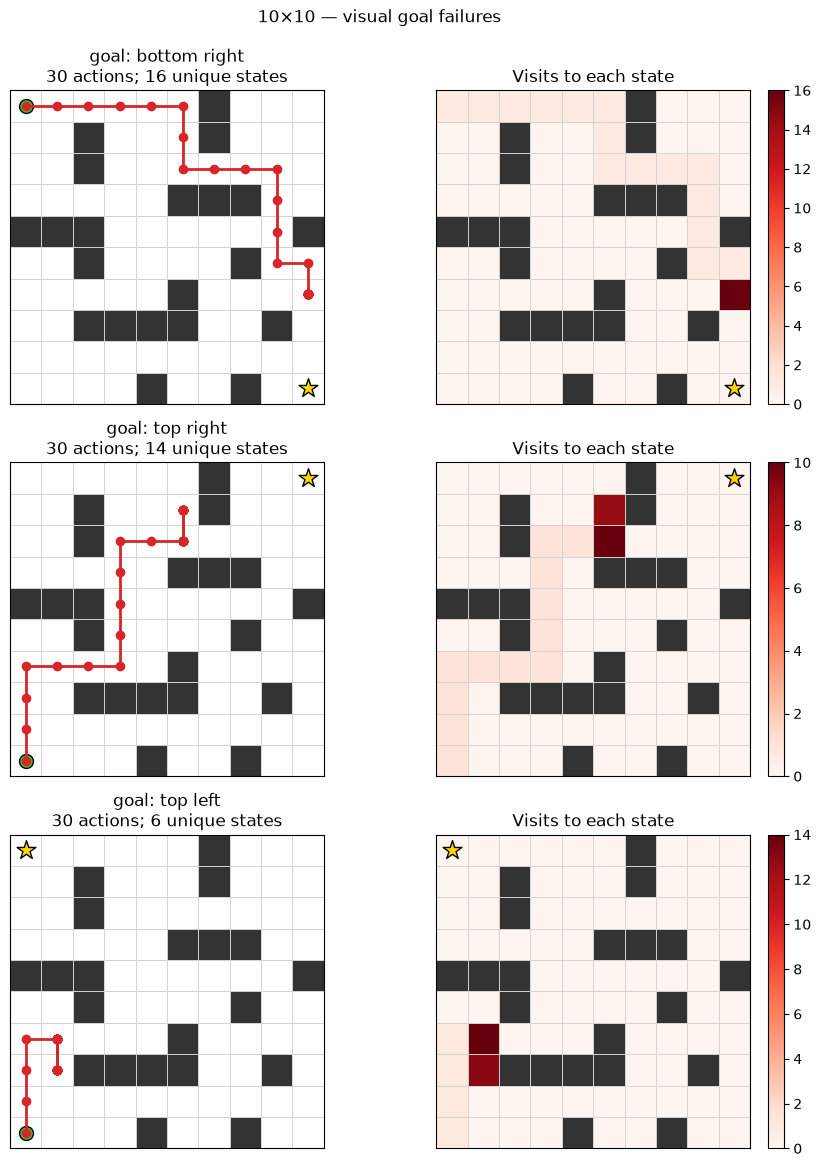

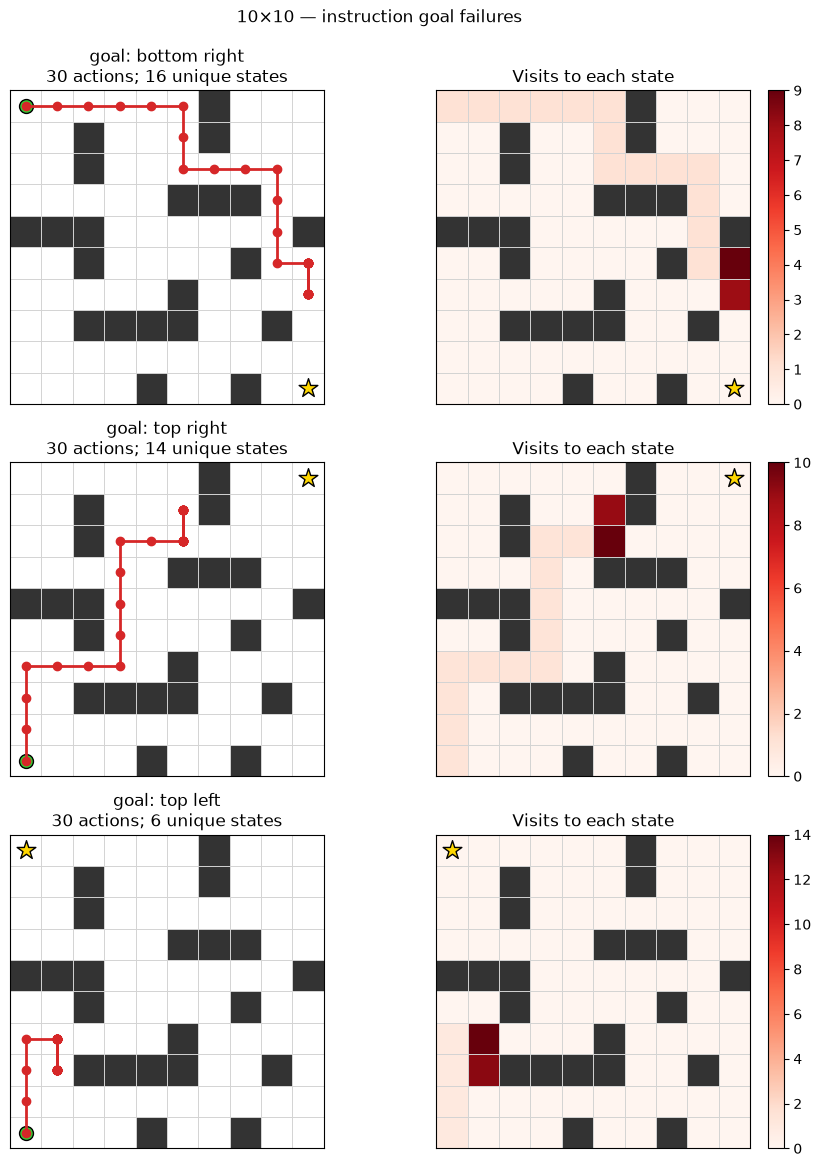

In [18]:
EXPERIMENT_CONFIGURATIONS = [
    {
        "name": "7×7",
        "grid_size": 7,
        "goals": ((0, 0), (0, 6), (6, 6)),
        "obstacles": {(3, 0), (3, 1), (3, 2), (2, 2), (4, 2), (6, 4), (4, 5), (1, 4)},
        "epochs": 100,
        "maximum_steps": 20,
        "learning_rate": 3e-3,
    },
    {
        "name": "8×8",
        "grid_size": 8,
        "goals": ((0, 0), (0, 7), (7, 7)),
        "obstacles": {
            (3, 0), (3, 1), (3, 2),
            (3, 4), (2, 4), (4, 4), # (3, 3), (2, 3), (4, 3),
            (5, 4), (5, 3), (5, 2),
            (1, 1), (0, 5), # (1, 5),
            (7, 6), (3, 6), (3, 7),
        },
        "epochs": 120,
        "maximum_steps": 25,
        "learning_rate": 3e-3,
    },
    {
        "name": "10×10",
        "grid_size": 10,
        "goals": ((0, 0), (0, 9), (9, 9)),
        "obstacles": {
            (4, 0), (4, 1), (4, 2),
            (1, 2), (2, 2), (5, 2),
            (3, 5), (3, 6), (3, 7),
            (7, 2), (7, 3), (7, 4),
            (6, 5), (7, 5), (9, 4),
            (0, 6), (1, 6), (4, 9),
            (5, 7), (7, 8), (9, 7),
        },
        "epochs": 140,
        "maximum_steps": 30,
        "learning_rate": 3e-3,
    },
]

experiment_results = {}
for configuration in EXPERIMENT_CONFIGURATIONS:
    shared_obstacles = frozenset(configuration["obstacles"])
    experiment_world = VisualGoalGridWorld(
        grid_size=configuration["grid_size"],
        obstacles_by_goal=(shared_obstacles,) * len(configuration["goals"]),
        goals=configuration["goals"],
    )
    result = run_goal_conditioning_experiment(
        experiment_world,
        epochs=configuration["epochs"],
        learning_rate=configuration["learning_rate"],
        seed=SEED,
        maximum_steps=configuration["maximum_steps"],
        device=DEVICE,
    )
    experiment_results[configuration["name"]] = result

    print(f"\n{configuration['name']}: {len(result.demonstrations.actions)} examples")
    print(
        f"  visual goal: validation={result.visual_validation_accuracy:.3f}, "
        f"closed loop={result.visual_closed_loop_success:.3f}"
    )
    print(
        f"  instruction: validation={result.instruction_validation_accuracy:.3f}, "
        f"closed loop={result.instruction_closed_loop_success:.3f}"
    )
    plot_experiment_losses(result)

    visual_action = partial(
        visual_goal_policy_action, result.visual_policy, experiment_world
    )
    instruction_action = partial(
        instruction_policy_action, result.instruction_policy, experiment_world
    )
    plot_policy_rollouts(
        experiment_world,
        {"visual goal": visual_action, "instruction goal": instruction_action},
        start=(experiment_world.grid_size - 1, 0),
        maximum_steps=configuration["maximum_steps"],
    )
    action_functions = {
        "visual goal": visual_action,
        "instruction goal": instruction_action,
    }
    plot_policy_action_fields(experiment_world, action_functions)

    for policy_name, action_function in action_functions.items():
        _, policy_rollouts = evaluate_closed_loop(
            experiment_world,
            action_function,
            result.demonstrations.state_goal_pairs,
            maximum_steps=configuration["maximum_steps"],
        )
        failure_figure, _ = plot_failed_rollouts(
            experiment_world, policy_rollouts, maximum_examples=3
        )
        if failure_figure is None:
            print(f"  {policy_name}: no failed rollouts")
        else:
            failure_figure.suptitle(
                f"{configuration['name']} — {policy_name} failures", y=1.02
            )
    plt.show()

### Observation: recovering from stuck policies

Many failed rollouts remain in one cell because the policy repeatedly selects a blocked action, or alternate between two cells in a short loop. Increasing `maximum_steps` helps only when a policy follows a useful but unusually long route; it does not resolve a deterministic cycle.

A practical controller could detect repeated states or actions and temporarily choose another valid action, perhaps preferring a less recently visited neighboring state. This may improve task success, but it is an additional recovery heuristic rather than knowledge learned by the neural policy. It is therefore useful to report recovery-enhanced results separately and retain the original greedy rollouts as a diagnostic of what the model learned.

### Recovery experiment on the 10×10 world

The helper below normally follows the learned policy. It intervenes only after observing either three consecutive transitions that leave the agent in one cell or a repeated two-cell cycle. It then randomly selects a valid action, preferring a destination not visited recently. A fixed random seed makes the comparison reproducible.

Repeated **actions** alone are not treated as failure because several identical moves can form a valid straight path. The state history tells us whether those actions actually made progress. The comparison keeps the same step limit as the original 10×10 experiment, isolating the effect of recovery from the effect of a longer horizon.

     visual goal: original=0.496, with recovery=0.821
instruction goal: original=0.466, with recovery=0.675


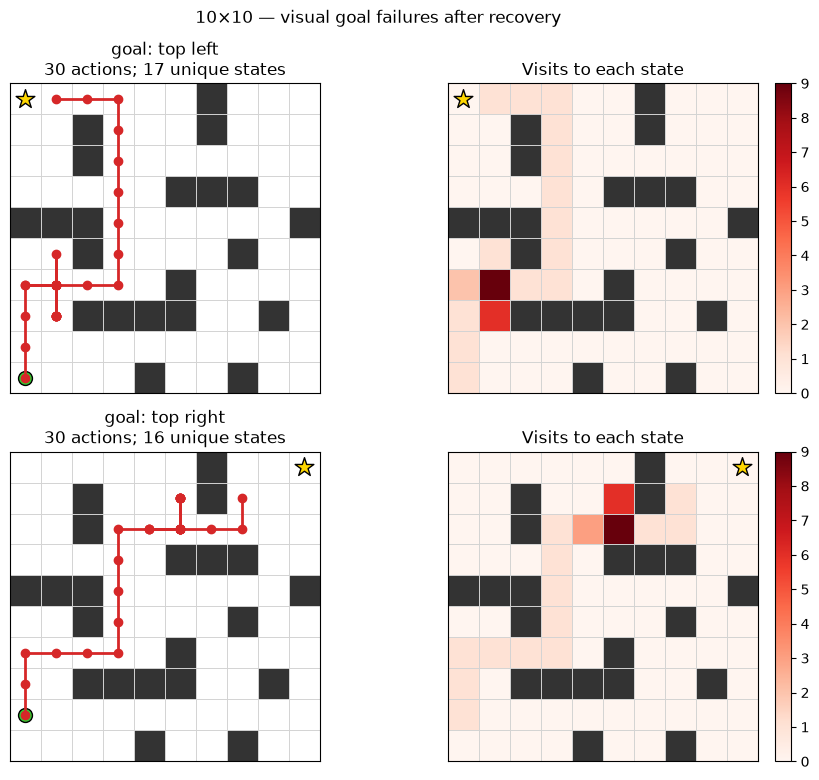

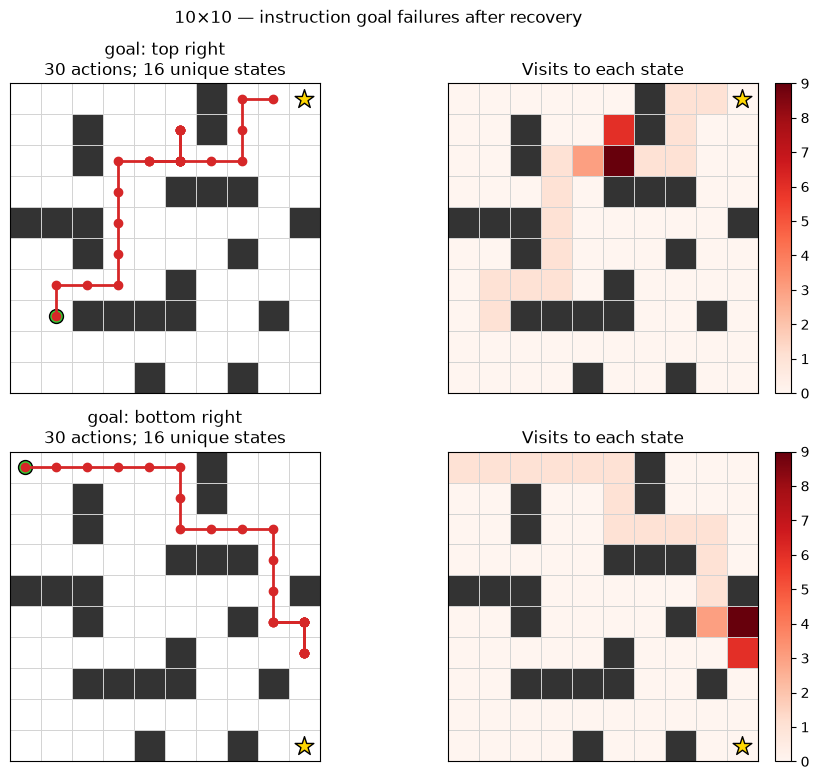

In [19]:
last_configuration = EXPERIMENT_CONFIGURATIONS[-1]
last_result = experiment_results[last_configuration["name"]]
last_world = last_result.world
last_actions = {
    "visual goal": partial(
        visual_goal_policy_action, last_result.visual_policy, last_world
    ),
    "instruction goal": partial(
        instruction_policy_action, last_result.instruction_policy, last_world
    ),
}

for policy_offset, (policy_name, action_function) in enumerate(last_actions.items()):
    recovered_rollouts = [
        rollout_policy_with_loop_recovery(
            last_world,
            action_function,
            state,
            goal_index,
            maximum_steps=last_configuration["maximum_steps"],
            seed=SEED + policy_offset * 10_000 + example_index,
        )
        for example_index, (state, goal_index) in enumerate(
            last_result.demonstrations.state_goal_pairs
        )
    ]
    recovered_success = np.mean(
        [rollout.succeeded for rollout in recovered_rollouts]
    )
    original_success = (
        last_result.visual_closed_loop_success
        if policy_name == "visual goal"
        else last_result.instruction_closed_loop_success
    )
    print(
        f"{policy_name:>16}: original={original_success:.3f}, "
        f"with recovery={recovered_success:.3f}"
    )
    recovery_failures, _ = plot_failed_rollouts(
        last_world, recovered_rollouts, maximum_examples=2
    )
    if recovery_failures is None:
        print("                  no failures remain after recovery")
    else:
        recovery_failures.suptitle(
            f"10×10 — {policy_name} failures after recovery", y=1.02
        )

plt.show()